In [19]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

In [20]:
# Tải dataset thô (dạng PIL Image để quan sát)
raw_train_dataset = torchvision.datasets.CIFAR10(root='../data', train=True, download=True)
raw_test_dataset = torchvision.datasets.CIFAR10(root='../data', train=False, download=True)

classes = raw_train_dataset.classes

print(f"Số lượng mẫu tập Train: {len(raw_train_dataset)}")
print(f"Số lượng mẫu tập Test: {len(raw_test_dataset)}")
print(f"Danh sách 10 lớp nhãn: {classes}")

# Kiểm tra 1 mẫu ảnh bất kỳ
sample_img, sample_label = raw_train_dataset[0]
print(f"Kích thước ảnh gốc (W x H): {sample_img.size}")
print(f"Nhãn ví dụ: {sample_label} -> Tên lớp: {classes[sample_label]}")

Số lượng mẫu tập Train: 50000
Số lượng mẫu tập Test: 10000
Danh sách 10 lớp nhãn: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Kích thước ảnh gốc (W x H): (32, 32)
Nhãn ví dụ: 6 -> Tên lớp: frog


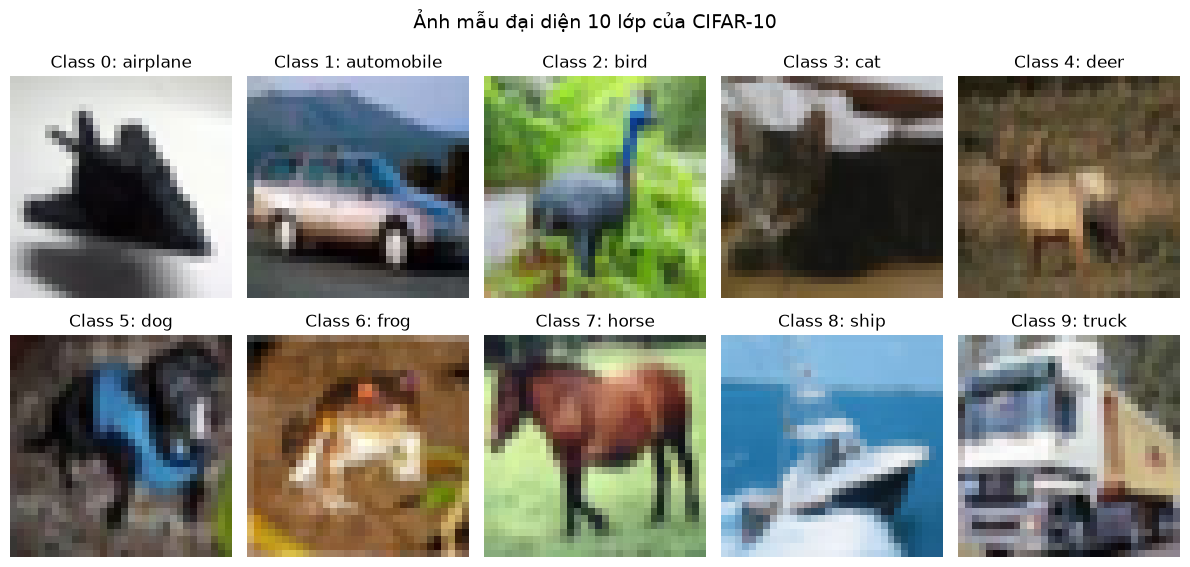

In [21]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
found_samples = {}

# Tìm 1 ảnh đại diện cho mỗi lớp từ 0 đến 9
for img, label in raw_train_dataset:
    if label not in found_samples:
        found_samples[label] = img
    if len(found_samples) == 10:
        break

for i, ax in enumerate(axes.flat):
    ax.imshow(found_samples[i])
    ax.set_title(f"Class {i}: {classes[i]}")
    ax.axis('off')

plt.suptitle("Ảnh mẫu đại diện 10 lớp của CIFAR-10", fontsize=14)
plt.tight_layout()
plt.savefig('../reports/figures/cifar10_samples.png')  # Lưu ảnh phục vụ báo cáo
plt.show()

In [22]:
# Định nghĩa pipeline biến đổi thử nghiệm
transform_pipeline = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5), # Augmentation
    transforms.ToTensor(),                  # Chuyển ảnh [0, 255] PIL sang Tensor [0.0, 1.0] dạng [C, H, W]
    transforms.Normalize(                   # Chuẩn hóa ImageNet
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    )
])

transformed_dataset = torchvision.datasets.CIFAR10(root='../data', train=True, transform=transform_pipeline)
img_tensor, label = transformed_dataset[0]

# Kiểm tra output theo đúng yêu cầu kiểm thử
print("--- Kết quả sau khi Preprocessing ---")
print(f"Tensor Shape: {img_tensor.shape}")  # Phải là torch.Size([3, 32, 32])
print(f"Data type: {img_tensor.dtype}")      # Phải là torch.float32
print(f"Giá trị Min: {img_tensor.min():.4f}, Max: {img_tensor.max():.4f}") # Sau normalize sẽ có giá trị âm/dương

--- Kết quả sau khi Preprocessing ---
Tensor Shape: torch.Size([3, 32, 32])
Data type: torch.float32
Giá trị Min: -2.1179, Max: 2.3936


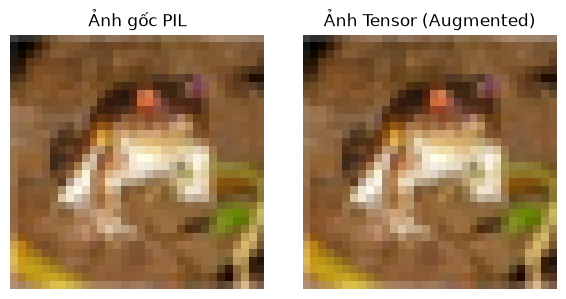

In [23]:
def imshow_tensor(tensor, title=None):
    # De-normalize để vẽ lại ảnh gốc
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    
    inp = tensor.numpy().transpose((1, 2, 0)) # Chuyển từ [C, H, W] sang [H, W, C]
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    
    plt.imshow(inp)
    if title:
        plt.title(title)
    plt.axis('off')

plt.figure(figsize=(6, 3))

plt.subplot(1, 2, 1)
plt.imshow(sample_img)
plt.title("Ảnh gốc PIL")
plt.axis('off')

plt.subplot(1, 2, 2)
imshow_tensor(img_tensor, "Ảnh Tensor (Augmented)")

plt.tight_layout()
plt.show()

### Tóm Tắt Pipeline Dữ Liệu
1. **Kích thước tập dữ liệu:** Train = 50,000 ảnh, Test = 10,000 ảnh.
2. **Kích thước đầu vào:** 3 kênh màu, $32 \times 32$ pixels (`[3, 32, 32]`).
3. **Danh mục các lớp:** 10 lớp (`airplane`, `automobile`, `bird`, `cat`, `deer`, `dog`, `frog`, `horse`, `ship`, `truck`).
4. **Chiến lược chuẩn hóa:** Chuẩn hóa theo tham số ImageNet (`mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`).